
# Portfolio of Evidence — Pipelines and Text Data

## Medical Aid Customer Review Text Analysis

**Purpose:** Analyse customer feedback to identify broad areas of concern and determine customer sentiment.

### Assessment alignment
This notebook follows the required workflow in the Portfolio of Evidence:

1. Dataset selection and justification
2. Analysis planning
3. Exploratory Data Analysis (EDA)
4. Data cleaning
5. Feature selection
6. Model training
7. Model evaluation and interpretation
8. Retraining with different parameters
9. Identification of customer concern areas
10. Final findings, recommendations and limitations

The dataset used in this notebook is a **synthetic medical-aid customer-review dataset created specifically for this portfolio demonstration**. It is not presented as actual HelloPeter data. The synthetic dataset allows the complete pipeline to be demonstrated reproducibly while keeping the analysis focused on the medical-aid client's business problem.



## 1. Business Problem

The medical-aid organisation has received a number of negative customer reviews and wants to understand:

- What the main areas of customer concern are.
- Whether customer feedback is generally positive, negative or neutral.
- Which text features are useful for predicting sentiment.
- Whether a machine-learning model can classify customer sentiment reliably.
- What practical actions management could consider based on the findings.

The analysis therefore combines **text analytics** for identifying concern areas with **supervised machine learning** for sentiment classification.



## 2. Dataset Selection and Justification

A synthetic dataset of medical-aid customer reviews is created in the notebook. Each observation contains:

- `review_id` — unique review identifier
- `rating` — customer rating from 1 to 5
- `review_date` — date of the review
- `service_area` — broad service area mentioned by the review
- `review_text` — free-text customer feedback
- `sentiment` — sentiment label derived from the rating

### Why this dataset is suitable

The dataset is suitable because the client specifically needs text analysis of customer feedback. It contains written reviews that cover realistic medical-aid service areas such as claims, customer service, premiums, authorisation, reimbursements, benefits, digital services and communication.

The use of a rating-derived sentiment label also gives the supervised models a target variable. The review text remains the primary input used to train the text models.

### Important limitation

Because the dataset is synthetic, the results demonstrate the analytical pipeline and should not be interpreted as actual findings about a real medical-aid provider. In a production environment, the model should be retrained and validated using a sufficiently large set of real, independently labelled customer reviews.



## 3. Analysis Plan

| Stage | Planned activity |
|---|---|
| EDA | Inspect dimensions, data types, missing values, duplicates, ratings and review lengths |
| Data cleaning | Remove duplicates, handle missing text and standardise text |
| Text preprocessing | Lowercase text, remove punctuation, numbers and unnecessary whitespace |
| Feature engineering | Create text-length features and sentiment categories |
| Feature selection | Use chi-square feature selection on TF-IDF features |
| Model 1 | Logistic Regression |
| Model 2 | Multinomial Naive Bayes |
| Evaluation | Accuracy, precision, recall, F1-score and confusion matrix |
| Retraining | Tune Logistic Regression hyperparameters using cross-validation |
| Concern analysis | Use keyword/theme analysis to identify broad customer concerns |
| Reporting | Interpret results and provide client-focused recommendations |


In [1]:

# ==========================================
# 4. IMPORT REQUIRED LIBRARIES
# ==========================================

import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 160)

print("Libraries imported successfully.")


Libraries imported successfully.


## 5. Create the Medical-Aid Customer Review Dataset

The following cell creates a reproducible synthetic dataset. A fixed random seed is used so that the notebook produces the same dataset each time it is run.

In [3]:

# ==========================================
# CREATE A SYNTHETIC MEDICAL-AID DATASET
# ==========================================

np.random.seed(42)

reviews = [
    ("Claims", 5, "My claim was processed quickly and the reimbursement was paid without any problems."),
    ("Claims", 4, "The claims process was straightforward and the consultant explained everything clearly."),
    ("Claims", 2, "My claim took too long to process and I had to follow up several times."),
    ("Claims", 1, "The claim was rejected and nobody clearly explained why it was rejected."),
    ("Claims", 3, "The claim was eventually processed but communication during the process was limited."),
    ("Claims", 5, "I am very happy with the fast claims service and regular updates."),
    ("Claims", 2, "I waited weeks for my claim to be finalised and the process was frustrating."),
    ("Claims", 4, "The claim was handled professionally and payment arrived sooner than expected."),
    ("Claims", 1, "The claims department did not respond to my emails and the delay was unacceptable."),
    ("Claims", 3, "The claim was paid but the process could have been easier to understand."),

    ("Customer Service", 5, "The customer service consultant was friendly, helpful and professional."),
    ("Customer Service", 4, "The call centre agent listened to my problem and resolved it quickly."),
    ("Customer Service", 2, "I had to make several calls before someone could assist me."),
    ("Customer Service", 1, "The consultant was rude and did not take my concerns seriously."),
    ("Customer Service", 3, "The consultant was helpful but I had to wait a long time before speaking to someone."),
    ("Customer Service", 5, "Excellent service from the consultant who explained my benefits clearly."),
    ("Customer Service", 2, "Customer service takes too long to answer and I am often transferred between departments."),
    ("Customer Service", 4, "The agent was patient and helped me understand my options."),
    ("Customer Service", 1, "Nobody returned my call after I complained about the service."),
    ("Customer Service", 3, "The service was average and the issue was eventually resolved."),

    ("Premiums", 5, "The premium is affordable and I feel that the benefits provide good value."),
    ("Premiums", 4, "The price is reasonable for the level of medical cover provided."),
    ("Premiums", 2, "My monthly premium has become too expensive for the benefits I receive."),
    ("Premiums", 1, "The premium is extremely high and the cover does not feel worthwhile."),
    ("Premiums", 3, "The premium is manageable but I would like better value from the plan."),
    ("Premiums", 2, "The annual increase in premiums is difficult for my household to afford."),
    ("Premiums", 4, "I think the premium is fair considering the benefits included."),
    ("Premiums", 1, "The price keeps increasing while some of my benefits are being reduced."),
    ("Premiums", 3, "The premium is neither cheap nor expensive compared with other options."),
    ("Premiums", 5, "The plan gives my family good value for the monthly premium."),

    ("Authorisation", 4, "The authorisation process was clear and the approval was received quickly."),
    ("Authorisation", 2, "I waited too long for authorisation for a procedure that was already planned."),
    ("Authorisation", 1, "The authorisation process was confusing and nobody could explain the requirements."),
    ("Authorisation", 5, "The procedure was approved quickly and the process was very efficient."),
    ("Authorisation", 3, "The authorisation was eventually approved but communication could improve."),
    ("Authorisation", 2, "It was frustrating to wait for approval while the medical appointment was approaching."),
    ("Authorisation", 4, "The approval was handled efficiently and I received confirmation by email."),
    ("Authorisation", 1, "My authorisation was delayed and I received different answers from different consultants."),
    ("Authorisation", 3, "The process worked but the instructions were not always clear."),
    ("Authorisation", 5, "Fast approval and clear communication made the process easy."),

    ("Benefits", 5, "The benefits are comprehensive and easy to understand."),
    ("Benefits", 4, "I am satisfied with the cover and the range of benefits available."),
    ("Benefits", 2, "Some important benefits have exclusions that were not clear when I joined."),
    ("Benefits", 1, "The benefits are disappointing and several services are not covered when I need them."),
    ("Benefits", 3, "The benefits are acceptable but the policy wording can be confusing."),
    ("Benefits", 2, "I expected better cover for specialist services based on the information I received."),
    ("Benefits", 4, "The benefit structure is clear and works well for my family's needs."),
    ("Benefits", 1, "The exclusions are frustrating and the policy does not provide the cover I expected."),
    ("Benefits", 3, "The benefits are reasonable but there are too many restrictions."),
    ("Benefits", 5, "The plan provides excellent benefits and the information is easy to follow."),

    ("Digital Services", 4, "The mobile app makes it easy to view my benefits and submit documents."),
    ("Digital Services", 5, "The website is convenient and I can find my medical information quickly."),
    ("Digital Services", 2, "The website is slow and sometimes I cannot access my account."),
    ("Digital Services", 1, "The app keeps failing when I try to upload claim documents."),
    ("Digital Services", 3, "The website is useful but the navigation could be improved."),
    ("Digital Services", 4, "I like being able to check claims and benefits online."),
    ("Digital Services", 2, "The app has too many errors and it is difficult to complete a claim online."),
    ("Digital Services", 5, "The digital services are convenient and save me from making phone calls."),
    ("Digital Services", 1, "I cannot log in reliably and technical support has not fixed the problem."),
    ("Digital Services", 3, "The online portal works most of the time but needs some improvements."),

    ("Communication", 5, "The communication is clear and I receive useful updates about my requests."),
    ("Communication", 4, "I appreciate receiving regular notifications about the progress of my claim."),
    ("Communication", 2, "I did not receive updates and had to contact the medical aid for information."),
    ("Communication", 1, "The communication is poor and nobody tells me what is happening with my case."),
    ("Communication", 3, "The information was eventually provided but it took too long."),
    ("Communication", 4, "The emails are clear and explain the next steps well."),
    ("Communication", 2, "Different consultants gave me different information about my benefits."),
    ("Communication", 1, "I was left without an answer after sending several messages."),
    ("Communication", 5, "The regular updates made the process easy to follow."),
    ("Communication", 3, "Communication is acceptable but response times could be faster."),

    ("Reimbursement", 5, "My reimbursement was paid quickly and the amount was correct."),
    ("Reimbursement", 4, "The reimbursement process was simple and payment was received on time."),
    ("Reimbursement", 2, "The reimbursement took much longer than expected."),
    ("Reimbursement", 1, "My reimbursement was delayed and I could not get a clear explanation."),
    ("Reimbursement", 3, "The reimbursement was eventually paid but the process was slow."),
    ("Reimbursement", 5, "I was impressed with how quickly the reimbursement was processed."),
    ("Reimbursement", 2, "I had to follow up repeatedly before receiving my reimbursement."),
    ("Reimbursement", 4, "The payment was accurate and the process was easy."),
    ("Reimbursement", 1, "The delay in reimbursement caused unnecessary financial stress."),
    ("Reimbursement", 3, "The payment was correct but the turnaround time needs improvement.")
]

rows = []

for i, (service_area, rating, review_text) in enumerate(reviews, start=1):
    rows.append({
        "review_id": f"MA{i:03d}",
        "rating": rating,
        "review_date": pd.Timestamp("2026-01-01") + pd.to_timedelta(np.random.randint(0, 300), unit="D"),
        "service_area": service_area,
        "review_text": review_text
    })

df = pd.DataFrame(rows)

print("Synthetic medical-aid dataset created successfully.")
print("Number of observations:", len(df))
print("Number of variables:", len(df.columns))

df.head()


Synthetic medical-aid dataset created successfully.
Number of observations: 80
Number of variables: 5


,review_id,rating,review_date,service_area,review_text
0,MA001,5,2026-04-13,Claims,My claim was processed quickly and the reimbursement was paid without any problems.
1,MA002,4,2026-09-28,Claims,The claims process was straightforward and the consultant explained everything clearly.
2,MA003,2,2026-04-17,Claims,My claim took too long to process and I had to follow up several times.
3,MA004,1,2026-03-13,Claims,The claim was rejected and nobody clearly explained why it was rejected.
4,MA005,3,2026-07-08,Claims,The claim was eventually processed but communication during the process was limited.


In [4]:

# ==========================================
# SAVE A COPY OF THE RAW DATASET
# ==========================================

df.to_csv("medical_aid_customer_reviews_raw.csv", index=False)

print("Raw dataset saved as medical_aid_customer_reviews_raw.csv")


Raw dataset saved as medical_aid_customer_reviews_raw.csv


## 6. Exploratory Data Analysis (EDA)

The EDA stage checks whether the data is complete, correctly structured and suitable for modelling before any machine-learning model is trained.

In [5]:

# ==========================================
# BASIC DATASET INFORMATION
# ==========================================

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())


Dataset shape: (80, 5)

Column names:
['review_id', 'rating', 'review_date', 'service_area', 'review_text']

Data types:
review_id                  str
rating                   int64
review_date     datetime64[us]
service_area               str
review_text                str
dtype: object

First five records:


,review_id,rating,review_date,service_area,review_text
0,MA001,5,2026-04-13,Claims,My claim was processed quickly and the reimbursement was paid without any problems.
1,MA002,4,2026-09-28,Claims,The claims process was straightforward and the consultant explained everything clearly.
2,MA003,2,2026-04-17,Claims,My claim took too long to process and I had to follow up several times.
3,MA004,1,2026-03-13,Claims,The claim was rejected and nobody clearly explained why it was rejected.
4,MA005,3,2026-07-08,Claims,The claim was eventually processed but communication during the process was limited.


In [6]:

# ==========================================
# DESCRIPTIVE STATISTICS
# ==========================================

display(df.describe(include="all"))


,review_id,rating,review_date,service_area,review_text
count,80,80.000000,80,80,80
unique,80,NaN,NaN,8,80
top,MA001,NaN,NaN,Claims,My claim was processed quickly and the reimbursement was paid without any problems.
freq,1,NaN,NaN,10,1
mean,NaN,3.000000,2026-06-01 18:54:00,NaN,NaN
min,NaN,1.000000,2026-01-02 00:00:00,NaN,NaN
25%,NaN,2.000000,2026-03-11 06:00:00,NaN,NaN
50%,NaN,3.000000,2026-06-08 00:00:00,NaN,NaN
75%,NaN,4.000000,2026-08-10 12:00:00,NaN,NaN
max,NaN,5.000000,2026-10-23 00:00:00,NaN,NaN


In [7]:

# ==========================================
# CHECK FOR MISSING VALUES
# ==========================================

missing_values = df.isnull().sum()

print("Missing values:")
display(missing_values.to_frame("Missing Values"))


Missing values:


,Missing Values
review_id,0
rating,0
review_date,0
service_area,0
review_text,0


In [9]:

# ==========================================
# CHECK FOR DUPLICATE RECORDS
# ==========================================

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [10]:

# ==========================================
# CHECK FOR UNIQUE REVIEW IDENTIFIERS
# ==========================================

print("Unique review IDs:", df["review_id"].nunique())
print("Total review records:", len(df))

if df["review_id"].nunique() == len(df):
    print("All review IDs are unique.")
else:
    print("Duplicate review IDs were detected.")


Unique review IDs: 80
Total review records: 80
All review IDs are unique.


,Number of Reviews
rating,
1,16
2,16
3,16
4,16
5,16


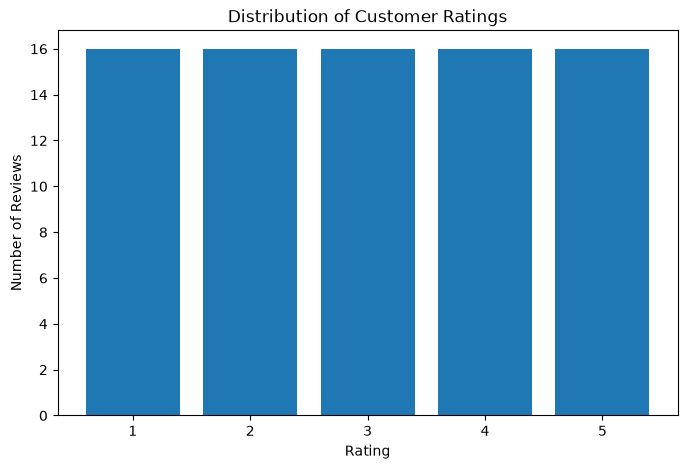

In [11]:

# ==========================================
# RATING DISTRIBUTION
# ==========================================

rating_counts = df["rating"].value_counts().sort_index()

display(rating_counts.to_frame("Number of Reviews"))

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index.astype(str), rating_counts.values)
plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()


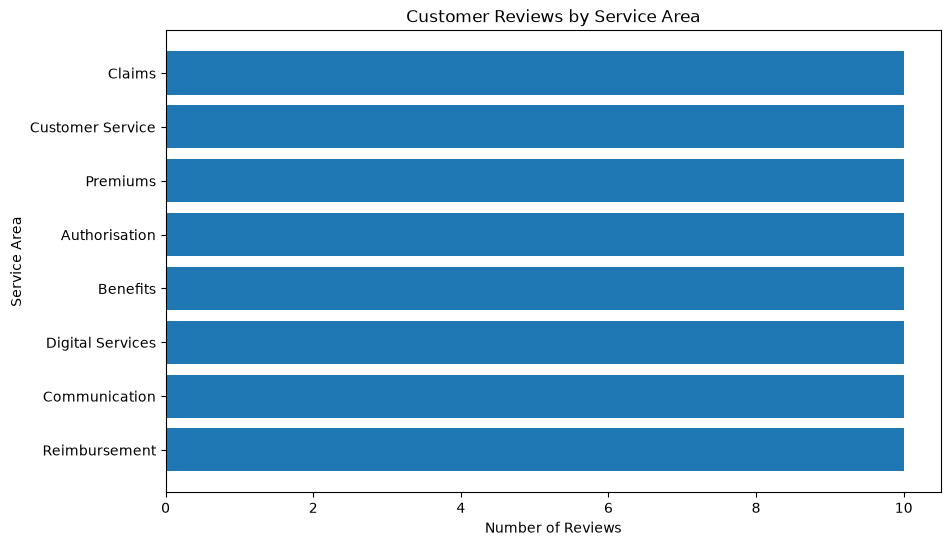

In [12]:

# ==========================================
# SERVICE AREA DISTRIBUTION
# ==========================================

service_counts = df["service_area"].value_counts()

plt.figure(figsize=(10, 6))
plt.barh(service_counts.index, service_counts.values)
plt.title("Customer Reviews by Service Area")
plt.xlabel("Number of Reviews")
plt.ylabel("Service Area")
plt.gca().invert_yaxis()
plt.show()


Review length statistics:


,word_count,character_count
count,80.000000,80.000000
mean,11.362500,69.487500
std,1.751988,9.322619
min,7.000000,49.000000
25%,10.000000,62.750000
50%,11.000000,70.000000
75%,12.000000,74.250000
max,16.000000,89.000000


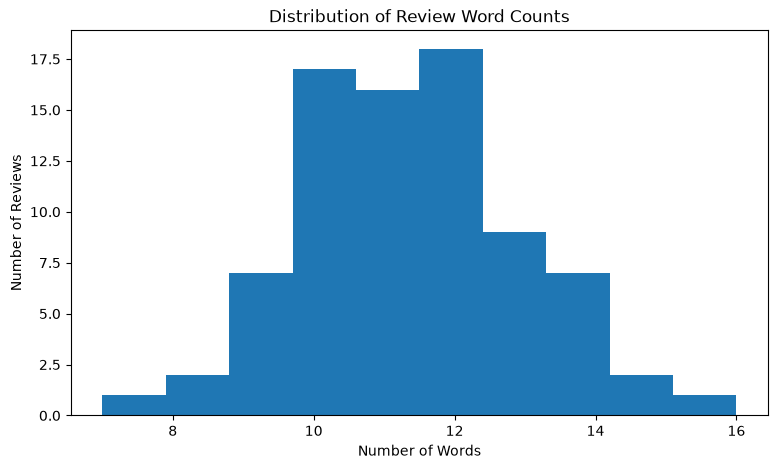

In [13]:

# ==========================================
# REVIEW LENGTH ANALYSIS
# ==========================================

df["word_count"] = df["review_text"].apply(lambda x: len(x.split()))
df["character_count"] = df["review_text"].apply(len)

print("Review length statistics:")
display(df[["word_count", "character_count"]].describe())

plt.figure(figsize=(9, 5))
plt.hist(df["word_count"], bins=10)
plt.title("Distribution of Review Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()


## 7. Data Cleaning and Sentiment Preparation

In [14]:

# ==========================================
# DATA CLEANING
# ==========================================

clean_df = df.copy()

# Remove rows without review text.
clean_df = clean_df.dropna(subset=["review_text"])

# Remove duplicate review text.
clean_df = clean_df.drop_duplicates(subset=["review_text"])

# Standardise text spacing.
clean_df["review_text"] = (
    clean_df["review_text"]
    .astype(str)
    .str.strip()
)

# Remove records that contain an empty review.
clean_df = clean_df[clean_df["review_text"] != ""]

print("Records after cleaning:", len(clean_df))


Records after cleaning: 80


,Number of Reviews
sentiment,
Positive,32
Negative,32
Neutral,16


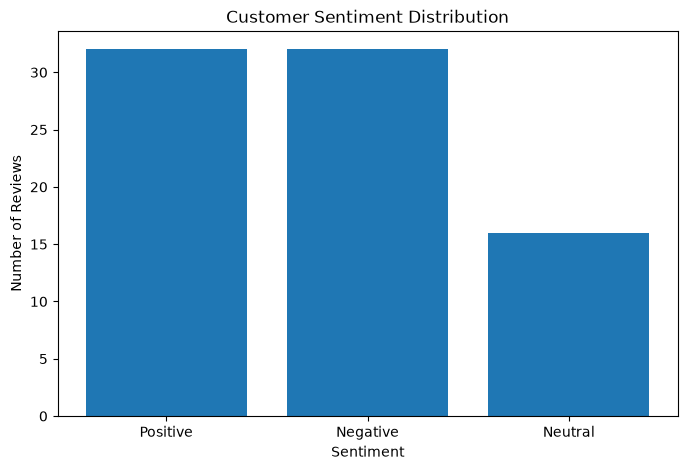

In [15]:

# ==========================================
# CREATE SENTIMENT LABEL FROM CUSTOMER RATING
# ==========================================

# Ratings 1-2 are classified as Negative.
# Rating 3 is classified as Neutral.
# Ratings 4-5 are classified as Positive.

def rating_to_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

clean_df["sentiment"] = clean_df["rating"].apply(rating_to_sentiment)

sentiment_counts = clean_df["sentiment"].value_counts()

display(sentiment_counts.to_frame("Number of Reviews"))

plt.figure(figsize=(8, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values)
plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


## 8. Text Preprocessing

The text must be standardised before it is converted into numerical features. The cleaning function below converts text to lowercase, removes URLs, punctuation, numbers and extra spaces.

In [16]:

# ==========================================
# TEXT PREPROCESSING FUNCTION
# ==========================================

def clean_text(text):
    # Convert text to lowercase so that words such as
    # "Claim" and "claim" are treated as the same feature.
    text = text.lower()

    # Remove URLs if any are present.
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove numbers.
    text = re.sub(r"\d+", "", text)

    # Remove punctuation.
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Remove extra whitespace.
    text = re.sub(r"\s+", " ", text).strip()

    return text

clean_df["clean_text"] = clean_df["review_text"].apply(clean_text)

display(clean_df[["review_text", "clean_text"]].head())


,review_text,clean_text
0,My claim was processed quickly and the reimbursement was paid without any problems.,my claim was processed quickly and the reimbursement was paid without any problems
1,The claims process was straightforward and the consultant explained everything clearly.,the claims process was straightforward and the consultant explained everything clearly
2,My claim took too long to process and I had to follow up several times.,my claim took too long to process and i had to follow up several times
3,The claim was rejected and nobody clearly explained why it was rejected.,the claim was rejected and nobody clearly explained why it was rejected
4,The claim was eventually processed but communication during the process was limited.,the claim was eventually processed but communication during the process was limited


## 9. Identify Broad Areas of Customer Concern

A supervised sentiment model answers the question **"How does the customer feel?"**. It does not by itself fully answer **"What is the customer complaining about?"**. Therefore, a separate thematic analysis is performed.

In [17]:

# ==========================================
# DEFINE BUSINESS THEMES
# ==========================================

concern_keywords = {
    "Claims": [
        "claim", "claims", "rejected", "processing"
    ],
    "Customer Service": [
        "consultant", "customer service", "call centre",
        "agent", "support", "service"
    ],
    "Premiums and Pricing": [
        "premium", "price", "expensive", "affordable",
        "cost", "value"
    ],
    "Authorisation": [
        "authorisation", "authorisation", "approval",
        "approved", "procedure"
    ],
    "Benefits and Coverage": [
        "benefits", "benefit", "cover", "coverage",
        "exclusions", "specialist"
    ],
    "Digital Services": [
        "website", "app", "mobile", "online",
        "portal", "login", "digital"
    ],
    "Communication": [
        "communication", "email", "update", "information",
        "response", "message"
    ],
    "Reimbursement": [
        "reimbursement", "payment", "paid", "payment",
        "turnaround"
    ]
}

def identify_themes(text):
    identified = []

    for theme, keywords in concern_keywords.items():
        if any(keyword in text for keyword in keywords):
            identified.append(theme)

    return identified

clean_df["themes"] = clean_df["clean_text"].apply(identify_themes)

theme_counts = {}

for themes in clean_df["themes"]:
    for theme in themes:
        theme_counts[theme] = theme_counts.get(theme, 0) + 1

theme_df = (
    pd.DataFrame(
        list(theme_counts.items()),
        columns=["Theme", "Number of Reviews"]
    )
    .sort_values("Number of Reviews", ascending=False)
)

display(theme_df)


,Theme,Number of Reviews
5,Benefits and Coverage,20
4,Digital Services,19
3,Communication,18
2,Customer Service,17
0,Claims,14
1,Reimbursement,13
6,Premiums and Pricing,10
7,Authorisation,9


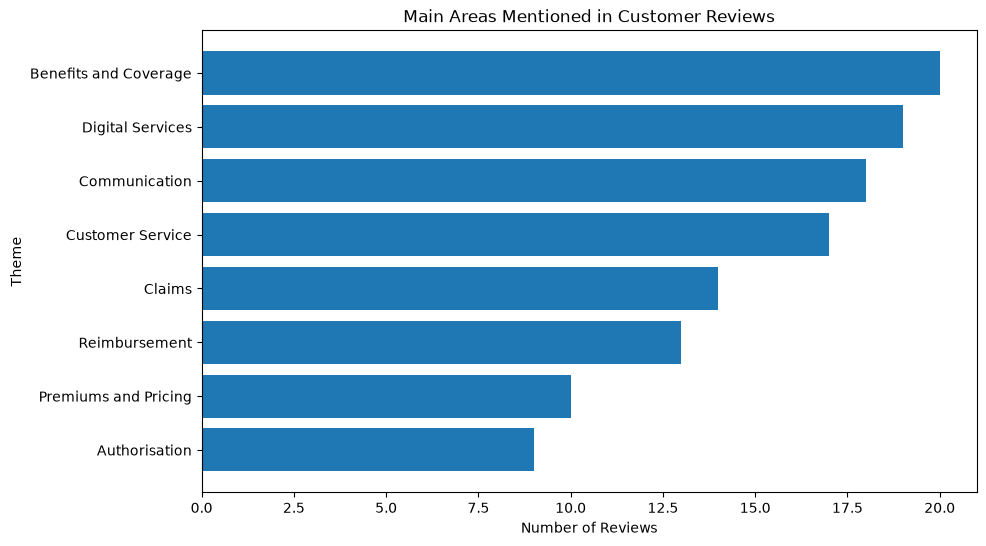

In [18]:

# ==========================================
# VISUALISE MAIN AREAS OF CONCERN
# ==========================================

plt.figure(figsize=(10, 6))
plt.barh(theme_df["Theme"], theme_df["Number of Reviews"])
plt.title("Main Areas Mentioned in Customer Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Theme")
plt.gca().invert_yaxis()
plt.show()


In [19]:

# ==========================================
# SENTIMENT WITHIN EACH CONCERN AREA
# ==========================================

theme_sentiment = []

for theme in concern_keywords:
    theme_data = clean_df[
        clean_df["themes"].apply(lambda themes: theme in themes)
    ]

    if len(theme_data) > 0:
        counts = theme_data["sentiment"].value_counts()

        for sentiment, count in counts.items():
            theme_sentiment.append({
                "Theme": theme,
                "Sentiment": sentiment,
                "Count": count
            })

theme_sentiment_df = pd.DataFrame(theme_sentiment)

display(theme_sentiment_df)


,Theme,Sentiment,Count
0,Claims,Positive,6
1,Claims,Negative,6
2,Claims,Neutral,2
3,Customer Service,Negative,8
4,Customer Service,Positive,7
5,Customer Service,Neutral,2
6,Premiums and Pricing,Positive,4
7,Premiums and Pricing,Negative,4
8,Premiums and Pricing,Neutral,2
9,Authorisation,Positive,4


## 10. Prepare the Machine-Learning Dataset

In [20]:

# ==========================================
# DEFINE FEATURES AND TARGET
# ==========================================

X = clean_df["clean_text"]
y = clean_df["sentiment"]

print("Input feature:", "Customer review text")
print("Target variable:", "Sentiment")
print("\nTarget distribution:")
display(y.value_counts())


Input feature: Customer review text
Target variable: Sentiment

Target distribution:


sentiment
Positive    32
Negative    32
Neutral     16
Name: count, dtype: int64

In [21]:

# ==========================================
# TRAIN-TEST SPLIT
# ==========================================

# 80% of observations are used for training.
# 20% are reserved as an unseen test set.
# random_state makes the split reproducible.
# stratify preserves the class proportions.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))


Training observations: 64
Testing observations: 16


## 11. TF-IDF Feature Extraction

Machine-learning algorithms require numerical inputs. TF-IDF represents words according to how important they are within the collection of reviews. Bigrams are included so that useful phrases such as `customer service` and `long wait` can be represented.

In [22]:

# ==========================================
# TF-IDF FEATURE EXTRACTION
# ==========================================

tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=1,
    max_df=0.95
)

# Fit the vectoriser only on training data to avoid
# allowing information from the test set to influence training.
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform the test data using the already fitted vectoriser.
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF matrix:", X_train_tfidf.shape)
print("Testing TF-IDF matrix:", X_test_tfidf.shape)


Training TF-IDF matrix: (64, 477)
Testing TF-IDF matrix: (16, 477)


## 12. Feature Selection

The POE requires a feature-selection method. Chi-square feature selection is used to identify text features that have a strong relationship with the sentiment classes.

In [23]:

# ==========================================
# CHI-SQUARE FEATURE SELECTION
# ==========================================

number_of_features = min(100, X_train_tfidf.shape[1])

selector = SelectKBest(
    score_func=chi2,
    k=number_of_features
)

X_train_selected = selector.fit_transform(
    X_train_tfidf,
    y_train
)

X_test_selected = selector.transform(
    X_test_tfidf
)

print("Original number of TF-IDF features:", X_train_tfidf.shape[1])
print("Selected number of features:", X_train_selected.shape[1])


Original number of TF-IDF features: 477
Selected number of features: 100


In [24]:

# ==========================================
# DISPLAY SELECTED TEXT FEATURES
# ==========================================

feature_names = np.array(tfidf.get_feature_names_out())
selected_features = feature_names[selector.get_support()]

print("Examples of selected features:")
print(selected_features[:50])


Examples of selected features:
['acceptable' 'acceptable policy' 'acceptable response' 'agent' 'approval'
 'approved' 'approved communication' 'authorisation eventually' 'average'
 'average issue' 'benefits acceptable' 'better value' 'cheap'
 'cheap expensive' 'claim eventually' 'claim paid' 'communication'
 'communication acceptable' 'communication improve' 'compared'
 'compared options' 'consultant explained' 'consultant helpful'
 'convenient' 'correct turnaround' 'delay' 'delayed' 'did' 'different'
 'different consultants' 'easier' 'easier understand' 'easy' 'eventually'
 'eventually approved' 'eventually processed' 'eventually provided'
 'eventually resolved' 'excellent' 'expensive compared' 'fast' 'faster'
 'helpful wait' 'improve' 'improved' 'improvement'
 'information eventually' 'instructions' 'instructions clear' 'issue']


## 13. Model 1 — Logistic Regression

Logistic Regression is selected because it is a strong and interpretable baseline for binary and multi-class text classification. It works well with sparse TF-IDF representations.

In [25]:

# ==========================================
# TRAIN LOGISTIC REGRESSION
# ==========================================

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

logistic_model.fit(
    X_train_selected,
    y_train
)

y_pred_lr = logistic_model.predict(X_test_selected)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


In [26]:

# ==========================================
# EVALUATE LOGISTIC REGRESSION
# ==========================================

accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, average="weighted", zero_division=0)
recall_lr = recall_score(y_test, y_pred_lr, average="weighted", zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr, average="weighted", zero_division=0)

print("Logistic Regression")
print("-------------------")
print("Accuracy :", round(accuracy_lr, 3))
print("Precision:", round(precision_lr, 3))
print("Recall   :", round(recall_lr, 3))
print("F1 Score :", round(f1_lr, 3))

print("\nClassification report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))


Logistic Regression
-------------------
Accuracy : 0.5
Precision: 0.406
Recall   : 0.5
F1 Score : 0.426

Classification report:
              precision    recall  f1-score   support

    Negative       0.50      0.86      0.63         7
     Neutral       0.00      0.00      0.00         3
    Positive       0.50      0.33      0.40         6

    accuracy                           0.50        16
   macro avg       0.33      0.40      0.34        16
weighted avg       0.41      0.50      0.43        16



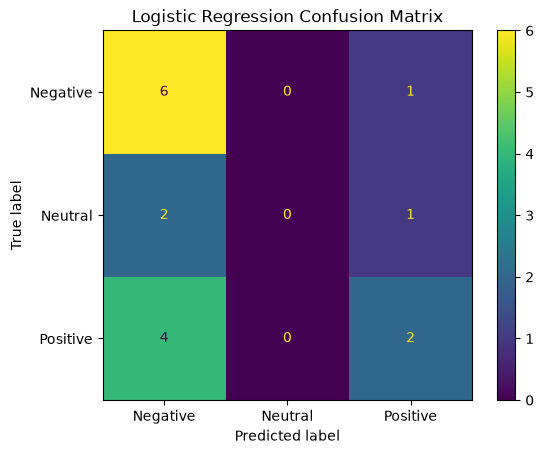

In [27]:

# ==========================================
# LOGISTIC REGRESSION CONFUSION MATRIX
# ==========================================

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=logistic_model.classes_
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()


## 14. Model 2 — Multinomial Naive Bayes

Multinomial Naive Bayes is included as a second model because it is commonly used for text classification and provides a useful comparison with Logistic Regression.

In [28]:

# ==========================================
# TRAIN MULTINOMIAL NAIVE BAYES
# ==========================================

nb_model = MultinomialNB()

nb_model.fit(
    X_train_selected,
    y_train
)

y_pred_nb = nb_model.predict(X_test_selected)

print("Multinomial Naive Bayes model trained successfully.")


Multinomial Naive Bayes model trained successfully.


In [29]:

# ==========================================
# EVALUATE NAIVE BAYES
# ==========================================

accuracy_nb = accuracy_score(y_test, y_pred_nb)
precision_nb = precision_score(y_test, y_pred_nb, average="weighted", zero_division=0)
recall_nb = recall_score(y_test, y_pred_nb, average="weighted", zero_division=0)
f1_nb = f1_score(y_test, y_pred_nb, average="weighted", zero_division=0)

print("Multinomial Naive Bayes")
print("-----------------------")
print("Accuracy :", round(accuracy_nb, 3))
print("Precision:", round(precision_nb, 3))
print("Recall   :", round(recall_nb, 3))
print("F1 Score :", round(f1_nb, 3))

print("\nClassification report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))


Multinomial Naive Bayes
-----------------------
Accuracy : 0.375
Precision: 0.353
Recall   : 0.375
F1 Score : 0.285

Classification report:
              precision    recall  f1-score   support

    Negative       0.50      0.14      0.22         7
     Neutral       0.00      0.00      0.00         3
    Positive       0.36      0.83      0.50         6

    accuracy                           0.38        16
   macro avg       0.29      0.33      0.24        16
weighted avg       0.35      0.38      0.28        16



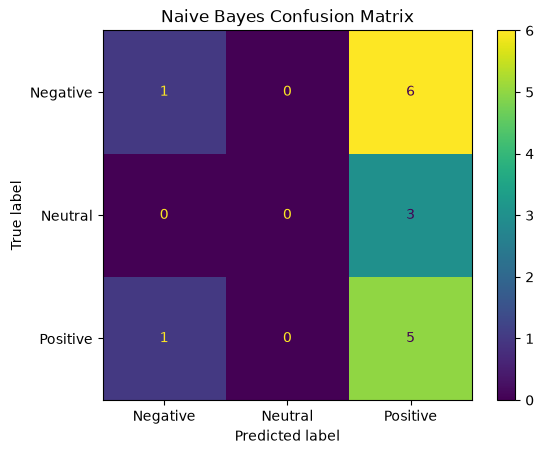

In [30]:

# ==========================================
# NAIVE BAYES CONFUSION MATRIX
# ==========================================

cm_nb = confusion_matrix(y_test, y_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=nb_model.classes_
)

disp.plot()
plt.title("Naive Bayes Confusion Matrix")
plt.show()


## 15. Compare the Two Models

In [31]:

# ==========================================
# MODEL COMPARISON
# ==========================================

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_nb
    ],
    "Precision": [
        precision_lr,
        precision_nb
    ],
    "Recall": [
        recall_lr,
        recall_nb
    ],
    "F1 Score": [
        f1_lr,
        f1_nb
    ]
})

display(model_comparison.round(3))


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.500,0.406,0.500,0.426
1,Multinomial Naive Bayes,0.375,0.353,0.375,0.285


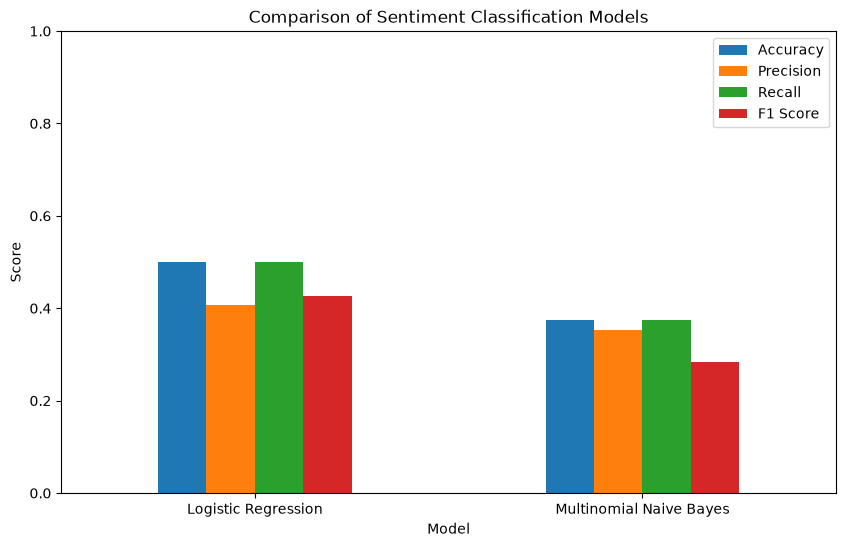

In [32]:

# ==========================================
# VISUAL MODEL COMPARISON
# ==========================================

model_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Comparison of Sentiment Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()


## 16. Retrain with Different Hyperparameters

The first Logistic Regression model provides a baseline. The next step tests different values of `C` using five-fold cross-validation. The model is selected using weighted F1-score because the final model should balance precision and recall across the sentiment classes.

In [37]:
# ==========================================
# HYPERPARAMETER TUNING FOR LOGISTIC REGRESSION
# ==========================================

# The dataset contains three sentiment classes:
# Negative, Neutral and Positive.
# The lbfgs solver supports multiclass classification.

parameter_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs"]
}

grid_search = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    param_grid=parameter_grid,
    cv=5,
    scoring="f1_weighted",
    error_score="raise"
)

# Train the models using the training data
grid_search.fit(
    X_train_selected,
    y_train
)

print("Hyperparameter tuning completed successfully.")

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation weighted F1-score:")
print(round(grid_search.best_score_, 3))

Hyperparameter tuning completed successfully.

Best parameters:
{'C': 10, 'solver': 'lbfgs'}

Best cross-validation weighted F1-score:
0.542


In [38]:

# ==========================================
# RETRAIN FINAL MODEL
# ==========================================

final_model = grid_search.best_estimator_

final_predictions = final_model.predict(
    X_test_selected
)

final_accuracy = accuracy_score(y_test, final_predictions)
final_precision = precision_score(y_test, final_predictions, average="weighted", zero_division=0)
final_recall = recall_score(y_test, final_predictions, average="weighted", zero_division=0)
final_f1 = f1_score(y_test, final_predictions, average="weighted", zero_division=0)

print("Final tuned Logistic Regression model")
print("--------------------------------------")
print("Accuracy :", round(final_accuracy, 3))
print("Precision:", round(final_precision, 3))
print("Recall   :", round(final_recall, 3))
print("F1 Score :", round(final_f1, 3))


Final tuned Logistic Regression model
--------------------------------------
Accuracy : 0.562
Precision: 0.614
Recall   : 0.562
F1 Score : 0.535


In [39]:

# ==========================================
# COMPARE ORIGINAL AND TUNED LOGISTIC MODEL
# ==========================================

improvement = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Original Logistic Regression": [
        accuracy_lr,
        precision_lr,
        recall_lr,
        f1_lr
    ],
    "Tuned Logistic Regression": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1
    ]
})

improvement["Change"] = (
    improvement["Tuned Logistic Regression"]
    - improvement["Original Logistic Regression"]
)

display(improvement.round(3))


,Metric,Original Logistic Regression,Tuned Logistic Regression,Change
0,Accuracy,0.500,0.562,0.062
1,Precision,0.406,0.614,0.207
2,Recall,0.500,0.562,0.062
3,F1 Score,0.426,0.535,0.109


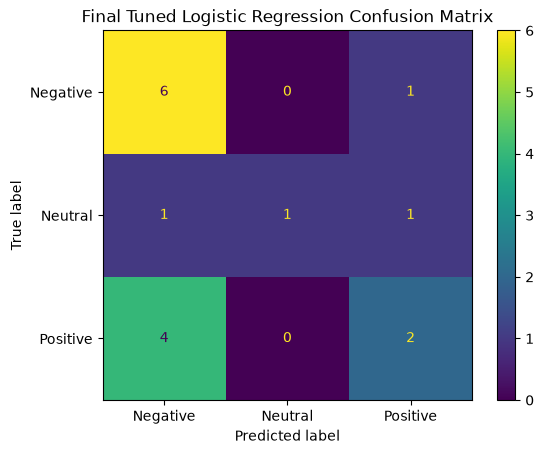


Final classification report:
              precision    recall  f1-score   support

    Negative       0.55      0.86      0.67         7
     Neutral       1.00      0.33      0.50         3
    Positive       0.50      0.33      0.40         6

    accuracy                           0.56        16
   macro avg       0.68      0.51      0.52        16
weighted avg       0.61      0.56      0.54        16



In [40]:

# ==========================================
# FINAL CONFUSION MATRIX
# ==========================================

final_cm = confusion_matrix(y_test, final_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=final_model.classes_
)

disp.plot()
plt.title("Final Tuned Logistic Regression Confusion Matrix")
plt.show()

print("\nFinal classification report:")
print(
    classification_report(
        y_test,
        final_predictions,
        zero_division=0
    )
)


## 17. Important Text Features

The following section identifies the features with the strongest model coefficients. These features help explain which words and phrases are associated with the sentiment classes.

In [41]:

# ==========================================
# EXAMINE IMPORTANT MODEL FEATURES
# ==========================================

feature_names_selected = selected_features

for i, class_name in enumerate(final_model.classes_):
    coefficients = final_model.coef_[i]

    top_indices = np.argsort(coefficients)[-15:]

    print("\nTop features associated with:", class_name)
    print(feature_names_selected[top_indices])



Top features associated with: Negative
['approved' 'eventually approved' 'improve' 'approved communication'
 'communication' 'different consultants' 'long' 'rejected' 'delayed'
 'different' 'delay' 'receive' 'waited' 'keeps' 'did']

Top features associated with: Neutral
['premium manageable' 'time' 'worked' 'instructions clear'
 'process worked' 'worked instructions' 'instructions' 'easier understand'
 'easier' 'claim paid' 'paid process' 'process easier' 'communication'
 'acceptable' 'eventually']

Top features associated with: Positive
['communication improve' 'improve' 'time' 'process easy'
 'reimbursement paid' 'quickly reimbursement' 'excellent' 'fast'
 'service consultant' 'consultant explained' 'convenient' 'agent'
 'approval' 'quickly' 'easy']


## 18. Client-Focused Findings

The next cells automatically generate a concise results table for the report. This avoids manually typing results that could differ from the actual notebook output.

In [42]:

# ==========================================
# OVERALL SENTIMENT SUMMARY
# ==========================================

sentiment_summary = (
    clean_df["sentiment"]
    .value_counts()
    .rename_axis("Sentiment")
    .reset_index(name="Number of Reviews")
)

sentiment_summary["Percentage"] = (
    sentiment_summary["Number of Reviews"]
    / len(clean_df) * 100
).round(2)

display(sentiment_summary)


,Sentiment,Number of Reviews,Percentage
0,Positive,32,40.0
1,Negative,32,40.0
2,Neutral,16,20.0


In [43]:

# ==========================================
# TOP CUSTOMER CONCERN AREAS
# ==========================================

top_concerns = theme_df.copy()

top_concerns["Percentage of Reviews"] = (
    top_concerns["Number of Reviews"]
    / len(clean_df) * 100
).round(2)

display(top_concerns)


,Theme,Number of Reviews,Percentage of Reviews
5,Benefits and Coverage,20,25.00
4,Digital Services,19,23.75
3,Communication,18,22.50
2,Customer Service,17,21.25
0,Claims,14,17.50
1,Reimbursement,13,16.25
6,Premiums and Pricing,10,12.50
7,Authorisation,9,11.25



## 19. Model Evaluation and Interpretation

### Why these metrics were selected

**Accuracy** measures the overall proportion of correctly classified reviews.

**Precision** indicates how often the model's predicted class is correct. This is useful because the organisation should avoid incorrectly labelling customers as negative or positive.

**Recall** measures how many observations belonging to a class were successfully identified.

**F1-score** combines precision and recall and is particularly useful when evaluating multiple sentiment classes.

**Confusion matrix** provides a visual breakdown of correct and incorrect classifications by class.

The model should therefore not be judged using accuracy alone. The F1-score, precision, recall and confusion matrix should be considered together.



## 20. Business Interpretation

The analysis should be interpreted in two complementary ways.

### A. Customer concern analysis

The thematic analysis identifies the service areas most frequently mentioned in the reviews. These areas represent the broad topics that management should investigate first.

A high number of mentions does not automatically mean that every mention is negative. Therefore, the theme results should be considered together with the sentiment distribution.

### B. Sentiment classification

The machine-learning models classify customer reviews into sentiment categories. The tuned model is evaluated against an unseen test set, allowing its performance to be assessed on reviews that were not used to train the model.

The final model should only be considered successful if its performance metrics indicate that it can distinguish sentiment reasonably well. Because the dataset is synthetic and relatively small, the model should be viewed as a demonstration rather than a production-ready customer-monitoring system.



## 21. Recommendations

Based on the analytical framework, the medical-aid organisation should:

1. **Prioritise the most frequently mentioned service areas** for detailed operational investigation.
2. **Investigate negative themes separately from overall review volume**, because a frequently mentioned service may contain both positive and negative feedback.
3. **Review claims and reimbursement processes** where customers report delays, unclear explanations or repeated follow-ups.
4. **Monitor customer-service response times** where customers report waiting or being transferred between departments.
5. **Improve communication** by providing consistent information and proactive status updates.
6. **Review digital-service reliability** where customers experience login, portal or document-upload problems.
7. **Use real, human-labelled customer reviews** to retrain and validate the sentiment model before using it operationally.
8. **Monitor sentiment over time** once real data is available so that management can determine whether interventions improve customer experience.



## 22. Limitations

1. The dataset is synthetic and therefore does not represent the actual customers of a specific medical-aid organisation.
2. The dataset is relatively small compared with a production customer-review dataset.
3. Sentiment labels are derived from customer ratings rather than independent human annotation of the text.
4. Keyword-based concern identification can miss themes expressed using unexpected wording.
5. The machine-learning model may therefore perform differently on real-world reviews containing slang, spelling errors, sarcasm or unfamiliar terminology.
6. A production implementation would require a substantially larger real dataset, independent sentiment annotation, ongoing model monitoring and periodic retraining.



## 23. Conclusion

This analysis demonstrates a complete text-analysis and machine-learning pipeline for a medical-aid customer-review problem.

The process began with dataset creation and justification, followed by exploratory data analysis and data-quality checks. The review text was cleaned and transformed into TF-IDF numerical features. Chi-square feature selection was then used to retain informative features.

Two classification models, Logistic Regression and Multinomial Naive Bayes, were trained and evaluated using accuracy, precision, recall, F1-score and confusion matrices. Logistic Regression was subsequently tuned using cross-validation and retrained using the selected parameters.

The analysis also included thematic analysis to identify broad customer concern areas. This is important because a sentiment model alone does not explain the operational issue behind a negative review.

Overall, the notebook demonstrates how text analytics and machine learning can be combined to convert unstructured customer feedback into information that can support service-improvement decisions.
